## Cell 1 — Connect Drive and define paths

In [1]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive", force_remount=True)

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "Amazon-Marketplace-Product-Intelligence-Platform-BJIT"
)

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports" / "recommendation"

RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

RAW_DATA_PATH = RAW_DATA_DIR / "amazon_products.csv"

Mounted at /content/drive


In [2]:
print("Project exists:", PROJECT_ROOT.exists())
print("Dataset path:", RAW_DATA_PATH)
print("Dataset exists:", RAW_DATA_PATH.exists())

if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {RAW_DATA_PATH}"
    )

Project exists: True
Dataset path: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/raw/amazon_products.csv
Dataset exists: True


In [3]:
import pandas as pd

products_raw = pd.read_csv(RAW_DATA_PATH)

print("Dataset loaded successfully")
print("Rows:", len(products_raw))
print("Columns:", len(products_raw.columns))

display(products_raw.head(3))

Dataset loaded successfully
Rows: 1056
Columns: 12


,asin,keyword,product_url,title,price,brand,description,image_url,video_url,avg_rating,rating_count,reviews
0,B0H9LHWBDK,wireless earbuds,https://www.amazon.com/dp/B0H9LHWBDK,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",$18.99,Brand: XIAOWTEK,LED Power Display and 50H Playback: Dual digit...,https://m.media-amazon.com/images/I/61odQgshCW...,https://m.media-amazon.com/images/S/vse-vms-tr...,4.8 out of 5 stars,(771),"[{""review_id"": ""R2CEXJGANFZ5NU"", ""reviewer_nam..."
1,B0HBWW3958,wireless earbuds,https://www.amazon.com/dp/B0HBWW3958,"Wireless Earbuds, Bluetooth 5.3 Headphones HiF...",$19.98,Brand: Fhumsh,Smart LED Display & 50H Sport Headphones: The ...,https://m.media-amazon.com/images/I/61D5ZCSIym...,https://m.media-amazon.com/images/S/vse-vms-tr...,4.3 out of 5 stars,(194),"[{""review_id"": ""R3N8ZPVF7TPV84"", ""reviewer_nam..."
2,B0H9RMD97X,wireless earbuds,https://www.amazon.com/dp/B0H9RMD97X,Air Pods for iPhone Bluetooth Wireless Ear Bud...,$13.99,Visit the Bioonis Store,【Balanced Hi-Fi Stereo Sound Earbuds】Experienc...,https://m.media-amazon.com/images/I/51wfpLrC24...,https://m.media-amazon.com/images/S/al-na-9d57...,4.3 out of 5 stars,NaN,[]


## Cell 3 — Validate required fields

In [4]:
CORE_FIELDS = [
    "asin",
    "title",
    "description",
    "brand",
    "keyword",
]

DISPLAY_FIELDS = [
    "price",
    "avg_rating",
    "rating_count",
    "image_url",
    "product_url",
]

expected_fields = CORE_FIELDS + DISPLAY_FIELDS

field_validation = pd.DataFrame({
    "field": expected_fields,
    "available": [
        field in products_raw.columns
        for field in expected_fields
    ],
    "purpose": [
        "Unique product identifier",
        "Primary recommendation text",
        "Product features and details",
        "Brand similarity signal",
        "Search-context similarity signal",
        "Displayed in recommendation card",
        "Displayed in recommendation card",
        "Displayed in recommendation card",
        "Displayed in recommendation card",
        "Amazon product link",
    ],
})

display(field_validation)

,field,available,purpose
0,asin,True,Unique product identifier
1,title,True,Primary recommendation text
2,description,True,Product features and details
3,brand,True,Brand similarity signal
4,keyword,True,Search-context similarity signal
5,price,True,Displayed in recommendation card
6,avg_rating,True,Displayed in recommendation card
7,rating_count,True,Displayed in recommendation card
8,image_url,True,Displayed in recommendation card
9,product_url,True,Amazon product link


## Cell 4 — Data-quality summary

In [5]:
quality_rows = []

for column in expected_fields:
    if column not in products_raw.columns:
        continue

    values = products_raw[column]
    non_empty = (
        values.notna()
        & values.astype(str).str.strip().ne("")
    )

    quality_rows.append({
        "field": column,
        "missing_rows": int((~non_empty).sum()),
        "available_rows": int(non_empty.sum()),
        "coverage_percentage": round(
            non_empty.mean() * 100,
            2,
        ),
    })

field_quality = pd.DataFrame(quality_rows)

dataset_summary = pd.DataFrame({
    "metric": [
        "Total rows",
        "Unique ASINs",
        "Duplicate ASIN rows",
        "Total keywords",
    ],
    "value": [
        len(products_raw),
        products_raw["asin"].nunique(),
        products_raw.duplicated("asin").sum(),
        products_raw["keyword"].nunique(),
    ],
})

display(dataset_summary)
display(field_quality)

,metric,value
0,Total rows,1056
1,Unique ASINs,981
2,Duplicate ASIN rows,75
3,Total keywords,28


,field,missing_rows,available_rows,coverage_percentage
0,asin,0,1056,100.00
1,title,1,1055,99.91
2,description,4,1052,99.62
3,brand,30,1026,97.16
4,keyword,0,1056,100.00
5,price,72,984,93.18
6,avg_rating,8,1048,99.24
7,rating_count,9,1047,99.15
8,image_url,1,1055,99.91
9,product_url,0,1056,100.00


## Interpretation

Dataset is sufficient for implementing Similar Product Recommendation.

Important decisions:

* The recommendation index will contain 981 unique products.
* We will not simply discard duplicated ASIN rows because one product may appear under multiple search keywords.
* Duplicate ASIN rows will be consolidated into one product.
* Their keywords will be combined into a keyword_list.
* Missing brands and descriptions will be filled safely.
* Products will not be removed because of missing prices.
* Price will be displayed but will not control the main similarity score.
* Reviews are not required for this feature.
* title, description, brand, and keyword will create the recommendation representation.
* The Excel keyword list is the collection source, not a separate model-training datase

## Step 2 — Preprocessing and focused EDA

What we are doing now:

* Clean recommendation-related fields.
* Parse price, rating and review count.
* Consolidate duplicate ASINs without losing their keywords.
* Create one recommendation text per product.
* Perform only the EDA needed for model selection.

## Cell 5 — Import libraries and cleaning functions

In [6]:
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


EMOJI_PATTERN = re.compile(
    "["
    "\U0001F300-\U0001F5FF"
    "\U0001F600-\U0001F64F"
    "\U0001F680-\U0001F6FF"
    "\U0001F700-\U0001F77F"
    "\U0001F780-\U0001F7FF"
    "\U0001F800-\U0001F8FF"
    "\U0001F900-\U0001F9FF"
    "\U0001FA00-\U0001FAFF"
    "\U00002600-\U000026FF"
    "\U00002700-\U000027BF"
    "]+",
    flags=re.UNICODE,
)


def normalize_text_value(value):
    if pd.isna(value):
        return ""

    text = str(value)

    # Normalize different Unicode representations.
    text = unicodedata.normalize("NFKC", text)

    # Remove HTML and URLs.
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove emojis.
    text = EMOJI_PATTERN.sub(" ", text)

    # Remove corrupted replacement characters.
    text = text.replace("\uFFFD", " ")

    # Remove invisible Unicode characters.
    text = re.sub(
        r"[\u200B-\u200F\u202A-\u202E\u2060\uFEFF]",
        " ",
        text,
    )

    # Remove control and surrogate characters.
    text = "".join(
        character
        if unicodedata.category(character)
        not in {"Cc", "Cs"}
        else " "
        for character in text
    )

    # Normalize whitespace.
    text = re.sub(r"\s+", " ", text).strip()

    return text


def clean_text_series(series):
    return series.map(normalize_text_value)


def extract_number(series):
    cleaned = (
        series
        .fillna("")
        .astype(str)
        .str.replace(",", "", regex=False)
    )

    return pd.to_numeric(
        cleaned.str.extract(
            r"(\d+(?:\.\d+)?)",
            expand=False,
        ),
        errors="coerce",
    )


def clean_url_series(series):
    cleaned = (
        series
        .fillna("")
        .astype(str)
        .str.strip()
    )

    return cleaned.where(
        cleaned.str.startswith(
            ("http://", "https://")
        ),
        "",
    )


def clean_brand(series):
    cleaned = clean_text_series(series)

    cleaned = cleaned.str.replace(
        r"(?i)^brand:\s*",
        "",
        regex=True,
    )

    cleaned = cleaned.str.replace(
        r"(?i)^visit the\s+",
        "",
        regex=True,
    )

    cleaned = cleaned.str.replace(
        r"(?i)\s+store$",
        "",
        regex=True,
    )

    cleaned = cleaned.str.replace(
        r"(?i)^by\s+",
        "",
        regex=True,
    )

    cleaned = cleaned.str.replace(
        r"(?i)\s+format:\s*.*$",
        "",
        regex=True,
    )

    cleaned = cleaned.str.strip()

    invalid_values = {
        "",
        "n/a",
        "na",
        "none",
        "nan",
        "unknown",
    }

    return cleaned.mask(
        cleaned.str.lower().isin(invalid_values),
        "",
    )

## Cell 6 — Clean the product fields

In [7]:
products_work = products_raw.copy()

products_work["source_row_order"] = np.arange(
    len(products_work)
)

products_work["asin"] = (
    clean_text_series(products_work["asin"])
    .str.upper()
)

# Remove only rows without an ASIN.
products_work = products_work[
    products_work["asin"].ne("")
].copy()

products_work["title"] = clean_text_series(
    products_work["title"]
)

products_work["description"] = clean_text_series(
    products_work["description"]
)

products_work["brand"] = clean_brand(
    products_work["brand"]
)

products_work["keyword"] = (
    clean_text_series(products_work["keyword"])
    .str.lower()
)

products_work["product_url"] = clean_url_series(
    products_work["product_url"]
)

products_work["image_url"] = clean_url_series(
    products_work["image_url"]
)

# Convert numeric-looking text to proper numbers.
products_work["price"] = extract_number(
    products_work["price"]
)

products_work["avg_rating"] = extract_number(
    products_work["avg_rating"]
)

products_work["rating_count"] = extract_number(
    products_work["rating_count"]
)

# Remove clearly invalid values.
products_work.loc[
    ~products_work["price"].between(0.01, 10000),
    "price",
] = np.nan

products_work.loc[
    ~products_work["avg_rating"].between(0, 5),
    "avg_rating",
] = np.nan

products_work.loc[
    products_work["rating_count"].lt(0),
    "rating_count",
] = np.nan

print("Field cleaning completed.")
display(products_work.head(3))

Field cleaning completed.


,asin,keyword,product_url,title,price,brand,description,image_url,video_url,avg_rating,rating_count,reviews,source_row_order
0,B0H9LHWBDK,wireless earbuds,https://www.amazon.com/dp/B0H9LHWBDK,"Wireless Earbuds, 2026 Bluetooth 5.4 Headphone...",18.99,XIAOWTEK,LED Power Display and 50H Playback: Dual digit...,https://m.media-amazon.com/images/I/61odQgshCW...,https://m.media-amazon.com/images/S/vse-vms-tr...,4.8,771.0,"[{""review_id"": ""R2CEXJGANFZ5NU"", ""reviewer_nam...",0
1,B0HBWW3958,wireless earbuds,https://www.amazon.com/dp/B0HBWW3958,"Wireless Earbuds, Bluetooth 5.3 Headphones HiF...",19.98,Fhumsh,Smart LED Display & 50H Sport Headphones: The ...,https://m.media-amazon.com/images/I/61D5ZCSIym...,https://m.media-amazon.com/images/S/vse-vms-tr...,4.3,194.0,"[{""review_id"": ""R3N8ZPVF7TPV84"", ""reviewer_nam...",1
2,B0H9RMD97X,wireless earbuds,https://www.amazon.com/dp/B0H9RMD97X,Air Pods for iPhone Bluetooth Wireless Ear Bud...,13.99,Bioonis,【Balanced Hi-Fi Stereo Sound Earbuds】Experienc...,https://m.media-amazon.com/images/I/51wfpLrC24...,https://m.media-amazon.com/images/S/al-na-9d57...,4.3,NaN,[],2


## Cell 7 — Consolidate duplicate ASINs

A product may appear under multiple search keywords. We will keep one product record while preserving all associated keywords.

In [8]:
products_work["completeness_score"] = (
    products_work["title"].ne("").astype(int)
    + products_work["description"].ne("").astype(int)
    + products_work["brand"].ne("").astype(int)
    + products_work["image_url"].ne("").astype(int)
    + products_work["product_url"].ne("").astype(int)
    + products_work["price"].notna().astype(int)
    + products_work["avg_rating"].notna().astype(int)
)

keyword_map = (
    products_work
    .groupby("asin")["keyword"]
    .agg(
        lambda values: " | ".join(
            sorted({
                value
                for value in values
                if value
            })
        )
    )
    .rename("keyword_list")
)

# Select the most complete record for every ASIN.
cleaned_products = (
    products_work
    .sort_values(
        [
            "asin",
            "completeness_score",
            "source_row_order",
        ],
        ascending=[True, False, True],
    )
    .drop_duplicates(
        subset=["asin"],
        keep="first",
    )
    .copy()
)

cleaned_products["keyword_primary"] = (
    cleaned_products["keyword"]
)

cleaned_products = (
    cleaned_products
    .drop(columns=["keyword"])
    .merge(
        keyword_map,
        on="asin",
        how="left",
    )
)

cleaned_products = cleaned_products.sort_values(
    "asin"
).reset_index(drop=True)

print("Duplicate ASIN consolidation completed.")
print("Unique product rows:", len(cleaned_products))
print(
    "Duplicate ASINs remaining:",
    cleaned_products["asin"].duplicated().sum(),
)

Duplicate ASIN consolidation completed.
Unique product rows: 981
Duplicate ASINs remaining: 0


## Cell 8 — Handle missing text and create recommendation text

In [9]:
cleaned_products["has_original_title"] = (
    cleaned_products["title"].ne("")
)

cleaned_products["has_description"] = (
    cleaned_products["description"].ne("")
)

cleaned_products["has_known_brand"] = (
    cleaned_products["brand"].ne("")
)

# Use description as a title fallback where possible.
missing_title = cleaned_products["title"].eq("")

cleaned_products.loc[
    missing_title,
    "title",
] = (
    cleaned_products.loc[
        missing_title,
        "description",
    ]
    .str.slice(0, 120)
)

# Final fallback guarantees every product has a display title.
still_missing_title = cleaned_products["title"].eq("")

cleaned_products.loc[
    still_missing_title,
    "title",
] = (
    "Amazon Product "
    + cleaned_products.loc[
        still_missing_title,
        "asin",
    ]
)

cleaned_products["brand"] = (
    cleaned_products["brand"]
    .replace("", "Unknown")
)

cleaned_products["keyword_list"] = (
    cleaned_products["keyword_list"]
    .fillna("")
)

brand_for_model = (
    cleaned_products["brand"]
    .replace("Unknown", "")
)

cleaned_products["recommendation_text"] = (
    cleaned_products["title"]
    + ". Brand: "
    + brand_for_model
    + ". Search context: "
    + cleaned_products["keyword_list"]
    + ". "
    + cleaned_products["description"]
)

cleaned_products["recommendation_text"] = (
    clean_text_series(
        cleaned_products["recommendation_text"]
    )
)

cleaned_products["recommendation_word_count"] = (
    cleaned_products["recommendation_text"]
    .str.split()
    .str.len()
)

cleaned_products["rating_count"] = (
    cleaned_products["rating_count"]
    .round()
    .astype("Int64")
)

print("Recommendation text created.")
display(
    cleaned_products[
        [
            "asin",
            "title",
            "description",
            "brand",
            "keyword_list",
            "recommendation_text",
            "recommendation_word_count",
        ]
    ].head()
)

Recommendation text created.


,asin,title,description,brand,keyword_list,recommendation_text,recommendation_word_count
0,8883707168,"""Moleskine Classic Notebook, Soft Cover, Large...",,Moleskine,notebook journal,"""Moleskine Classic Notebook, Soft Cover, Large...",20
1,B00005IBX9,Cuisinart DCC-1200P1 Brew Central 12-Cup Progr...,FULLY AUTOMATIC COFFEE BREWER: 24-hour program...,Cuisinart,coffee maker,Cuisinart DCC-1200P1 Brew Central 12-Cup Progr...,104
2,B00006IV0Q,Presto 02811 Stainless Steel 12-Cup Electric C...,RAPID BREWING: Our coffee percolator is design...,Presto,coffee maker,Presto 02811 Stainless Steel 12-Cup Electric C...,169
3,B00009J580,"Yamaha JR1 FG Junior 3/4 Size Acoustic Guitar,...",The FG Junior is a 3/4 sized guitar modeled af...,Yamaha,yamaha accoustic guitar,"Yamaha JR1 FG Junior 3/4 Size Acoustic Guitar,...",86
4,B0006ZAU22,Washburn Deep Forest Burl ACE Acoustic Electri...,Beautiful and exotic burl top with okoume back...,Washburn,yamaha accoustic guitar,Washburn Deep Forest Burl ACE Acoustic Electri...,52


## Cell 9 — Focused recommendation EDA

In [10]:
eda_summary = pd.DataFrame({
    "metric": [
        "Raw product rows",
        "Unique recommendation products",
        "Removed duplicate ASIN rows",
        "Products without original title",
        "Products without description",
        "Products with unknown brand",
        "Products without price",
        "Products without image",
        "Products without recommendation text",
    ],
    "value": [
        len(products_raw),
        len(cleaned_products),
        len(products_raw) - len(cleaned_products),
        int(
            (~cleaned_products["has_original_title"])
            .sum()
        ),
        int(
            (~cleaned_products["has_description"])
            .sum()
        ),
        int(
            (~cleaned_products["has_known_brand"])
            .sum()
        ),
        int(cleaned_products["price"].isna().sum()),
        int(cleaned_products["image_url"].eq("").sum()),
        int(
            cleaned_products[
                "recommendation_text"
            ].eq("").sum()
        ),
    ],
})

display(eda_summary)

display(
    cleaned_products[
        "recommendation_word_count"
    ]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.95]
    )
    .to_frame("value")
)

,metric,value
0,Raw product rows,1056
1,Unique recommendation products,981
2,Removed duplicate ASIN rows,75
3,Products without original title,0
4,Products without description,3
5,Products with unknown brand,29
6,Products without price,73
7,Products without image,0
8,Products without recommendation text,0


,value
count,981.000000
mean,218.384302
std,97.769054
min,17.000000
25%,153.000000
50%,216.000000
75%,278.000000
95%,383.000000
max,563.000000


## Cell 10 — Essential EDA visualizations

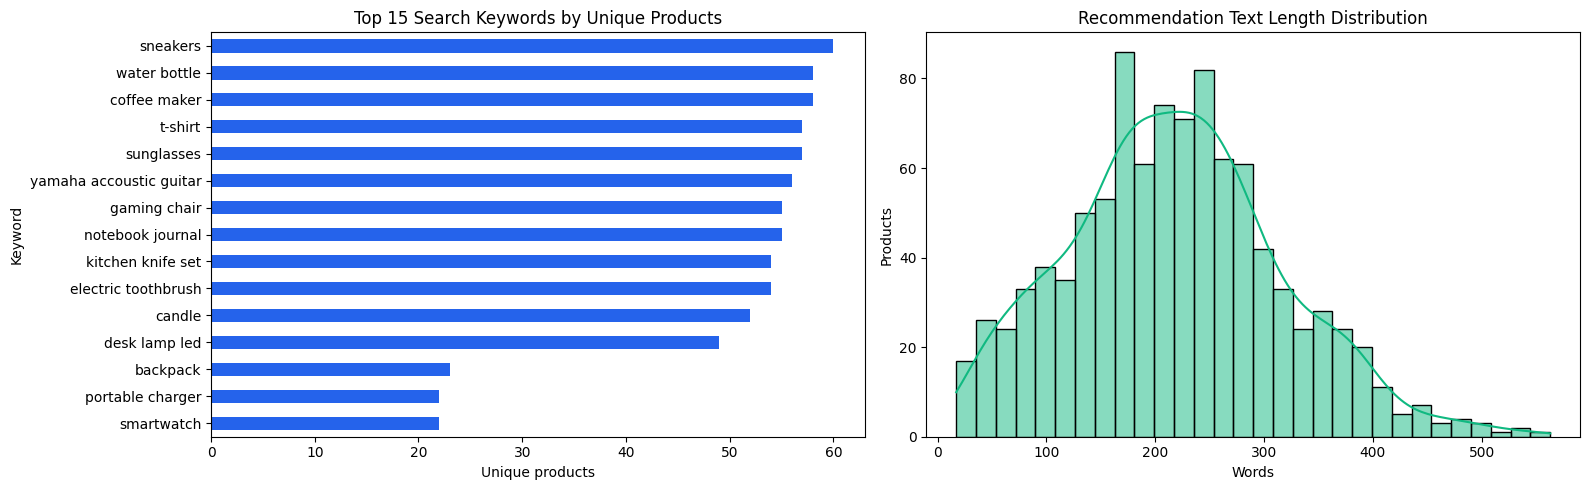

In [11]:
keyword_counts = (
    cleaned_products["keyword_list"]
    .str.split(" | ", regex=False)
    .explode()
    .str.strip()
)

keyword_counts = (
    keyword_counts[
        keyword_counts.ne("")
    ]
    .value_counts()
    .head(15)
    .sort_values()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5),
)

keyword_counts.plot(
    kind="barh",
    ax=axes[0],
    color="#2563EB",
)

axes[0].set_title(
    "Top 15 Search Keywords by Unique Products"
)
axes[0].set_xlabel("Unique products")
axes[0].set_ylabel("Keyword")

sns.histplot(
    cleaned_products["recommendation_word_count"],
    bins=30,
    kde=True,
    ax=axes[1],
    color="#10B981",
)

axes[1].set_title(
    "Recommendation Text Length Distribution"
)
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Products")

plt.tight_layout()
plt.show()

## Cell 11 — Final validation and save outputs

In [12]:
OUTPUT_COLUMNS = [
    "asin",
    "title",
    "description",
    "brand",
    "keyword_primary",
    "keyword_list",
    "price",
    "avg_rating",
    "rating_count",
    "image_url",
    "product_url",
    "recommendation_text",
    "recommendation_word_count",
    "has_original_title",
    "has_description",
    "has_known_brand",
]

recommendation_products = (
    cleaned_products[OUTPUT_COLUMNS]
    .copy()
)

# Necessary data validations.
assert recommendation_products["asin"].ne("").all()
assert recommendation_products["asin"].is_unique
assert recommendation_products["title"].ne("").all()
assert recommendation_products["product_url"].ne("").all()
assert recommendation_products["image_url"].ne("").mean() >= 0.95
assert (
    recommendation_products[
        "recommendation_text"
    ].ne("").all()
)
assert not recommendation_products["brand"].str.contains(
    r"(?i)brand:|visit the|format:",
    regex=True,
).any()
assert not recommendation_products.loc[
    recommendation_products["brand"].eq("Unknown"),
    "recommendation_text",
].str.contains("Brand: Unknown", regex=False).any()

CLEAN_DATA_PATH = (
    PROCESSED_DIR
    / "products_recommendation_clean.csv"
)

SUMMARY_PATH = (
    REPORT_DIR
    / "recommendation_preprocessing_summary.csv"
)

recommendation_products.to_csv(
    CLEAN_DATA_PATH,
    index=False,
    encoding="utf-8-sig",
)

eda_summary.to_csv(
    SUMMARY_PATH,
    index=False,
    encoding="utf-8-sig",
)

print("Preprocessing successful")
print("Cleaned rows:", len(recommendation_products))
print("Unique ASINs:", recommendation_products["asin"].nunique())
print("Cleaned dataset:", CLEAN_DATA_PATH)
print("EDA summary:", SUMMARY_PATH)
print("Products with images:", recommendation_products["image_url"].ne("").sum())
print("Products without images:", recommendation_products["image_url"].eq("").sum())
print("Suspicious brand values:", recommendation_products["brand"].str.contains(r"(?i)brand:|visit the|format:", regex=True).sum())

Preprocessing successful
Cleaned rows: 981
Unique ASINs: 981
Cleaned dataset: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/data/processed/products_recommendation_clean.csv
EDA summary: /content/drive/MyDrive/Amazon-Marketplace-Product-Intelligence-Platform-BJIT/reports/recommendation/recommendation_preprocessing_summary.csv
Products with images: 981
Products without images: 0
Suspicious brand values: 0


## Preprocessing and EDA Interpretation

The raw dataset contained 1,056 product rows representing 981 unique
ASINs. The duplicated ASIN rows occurred because some products appeared
under more than one collection keyword. These products were consolidated
into one recommendation record while preserving all associated keywords.

Title and description coverage were sufficiently high for content-based
recommendation. Missing brand values were represented as `Unknown`, while
missing titles used description or ASIN-based fallback values. Products
were not removed because of missing price, rating or image information,
as these fields are primarily used for presentation rather than the main
similarity calculation.

The final recommendation dataset contains one deterministic record per
ASIN. Product title, description, brand and collection keywords were
combined into a recommendation text field. Reviews were excluded because
the product metadata already provides the most direct and efficient
information for this feature.

In [13]:
saved_clean_data = pd.read_csv(
    CLEAN_DATA_PATH,
    keep_default_na=False,
)

moleskine_check = saved_clean_data[
    saved_clean_data["asin"]
    .astype(str)
    .eq("8883707168")
][
    [
        "asin",
        "title",
        "brand",
        "keyword_list",
    ]
]

suspicious_brand_count = int(
    saved_clean_data["brand"]
    .astype(str)
    .str.contains(
        r"(?i)brand:|visit the|format:",
        regex=True,
    )
    .sum()
)

unknown_brand_text_count = int(
    saved_clean_data.loc[
        saved_clean_data["brand"]
        .astype(str)
        .str.lower()
        .eq("unknown"),
        "recommendation_text",
    ]
    .astype(str)
    .str.contains(
        "Brand: Unknown",
        case=False,
        regex=False,
    )
    .sum()
)

verification_summary = pd.DataFrame({
    "check": [
        "Saved product rows",
        "Unique ASINs",
        "Duplicate ASINs",
        "Suspicious brand values",
        "Unknown brand included in model text",
        "Blank recommendation texts",
    ],
    "value": [
        len(saved_clean_data),
        saved_clean_data["asin"].nunique(),
        saved_clean_data["asin"].duplicated().sum(),
        suspicious_brand_count,
        unknown_brand_text_count,
        saved_clean_data[
            "recommendation_text"
        ].astype(str).str.strip().eq("").sum(),
    ],
})

display(moleskine_check)
display(verification_summary)

,asin,title,brand,keyword_list
0,8883707168,"""Moleskine Classic Notebook, Soft Cover, Large...",Moleskine,notebook journal


,check,value
0,Saved product rows,981
1,Unique ASINs,981
2,Duplicate ASINs,0
3,Suspicious brand values,0
4,Unknown brand included in model text,0
5,Blank recommendation texts,0
